# Première inspection d’un dataset

**Projet / problématique commune :** …

**Dataset :** …

**Responsable :** … · **Relecteur :** …

**Contributeurs :** … · **Date :** …

**Version des données :** …

**Référence du fichier / source :** …

## Inspection

In [2]:
import numpy as np
import pandas as pd

chemin_lovac = "../data/lovac-open-data-2020-a-2026.xlsx"

# ── Chargement : feuille communale, tout en texte (les "s" empêchent la lecture en nombres) ──
lovac_brut = pd.read_excel(chemin_lovac, sheet_name="COM open data", dtype=str)
print("Dimensions :", lovac_brut.shape)
print(list(lovac_brut.columns))
display(lovac_brut.head(3))

# Les autres feuilles : métadonnées et totaux nationaux, régionaux, départementaux
print(pd.ExcelFile(chemin_lovac).sheet_names)

# ── Structure : une ligne = une commune ? ────────────────────────────────────
print("Codes commune uniques :", lovac_brut["CODGEO_26"].nunique(), "/", len(lovac_brut))
print("Longueur des codes :", lovac_brut["CODGEO_26"].str.len().unique())
print("Doublons exacts :", lovac_brut.duplicated().sum())

# Colonnes de chiffres : celles qui commencent par pp_ (parc privé) ou ff_ (fichiers fonciers)
colonnes_chiffres = []
for col in lovac_brut.columns:
    if col.startswith("pp_") or col.startswith("ff_"):
        colonnes_chiffres.append(col)
print(len(colonnes_chiffres), "colonnes de chiffres")

# ── Secret statistique : part de "s" par colonne ─────────────────────────────
secret = pd.DataFrame({"nb_s": (lovac_brut[colonnes_chiffres] == "s").sum(),
                       "% s": ((lovac_brut[colonnes_chiffres] == "s").mean() * 100).round(1)})
display(secret)

# Y a-t-il d'autres textes que "s" dans les colonnes de chiffres ?
for col in colonnes_chiffres:
    valeurs = lovac_brut[col].dropna()
    autres = valeurs[(valeurs != "s") & (~valeurs.str.isdigit())]
    if len(autres) > 0:
        print(col, ": valeurs inattendues", autres.unique()[:5])

# Valeurs manquantes "vraies" (cases vides)
manquants = lovac_brut.isna().sum()
print(manquants[manquants > 0])

# ── Territoire ───────────────────────────────────────────────────────────────
print("Départements :", lovac_brut["DEP"].nunique())
print("Mayotte (976) présente ?", (lovac_brut["DEP"] == "976").sum() > 0)
print("Communes d'Alsace-Moselle :", lovac_brut["DEP"].isin(["57", "67", "68"]).sum())
plm = (lovac_brut["CODGEO_26"].str[:3].isin(["751", "132"])) | (lovac_brut["CODGEO_26"].str[:4] == "6938")
print("Arrondissements Paris / Lyon / Marseille :", plm.sum(),
      "| codes 75056/69123/13055 :", lovac_brut["CODGEO_26"].isin(["75056", "69123", "13055"]).sum())

# ── Totaux nationaux par millésime (feuille FR) ──────────────────────────────
fr = pd.read_excel(chemin_lovac, sheet_name="FR")
display(fr)

# ── Cohérence et distribution (exemple du millésime 2023) ────────────────────
vac = pd.to_numeric(lovac_brut["pp_vacant_23"].replace("s", np.nan))
vac2 = pd.to_numeric(lovac_brut["pp_vacant_plus_2ans_23"].replace("s", np.nan))
parc = pd.to_numeric(lovac_brut["ff_pp_total_23"].replace("s", np.nan))
print("Vacants 2 ans > vacants :", (vac2 > vac).sum(), "| vacants > parc :", (vac > parc).sum())

taux = vac / parc * 100
print(taux.quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(1))
# Les taux les plus élevés : quelles communes ?
extremes = lovac_brut.assign(taux=taux).sort_values("taux").dropna(subset=["taux"]).tail(5)
display(extremes[["CODGEO_26", "LIBGEO_26", "DEP", "pp_vacant_23", "ff_pp_total_23", "taux"]])

Dimensions : (34912, 28)
['CODGEO_26', 'LIBGEO_26', 'pp_vacant_26', 'pp_vacant_plus_2ans_26', 'ff_pp_total_25', 'pp_vacant_25', 'pp_vacant_plus_2ans_25', 'ff_pp_total_24', 'pp_vacant_24', 'pp_vacant_plus_2ans_24', 'ff_pp_total_23', 'pp_vacant_23', 'pp_vacant_plus_2ans_23', 'ff_pp_total_22', 'pp_vacant_22', 'pp_vacant_plus_2ans_22', 'ff_pp_total_21', 'pp_vacant_21', 'pp_vacant_plus_2ans_21', 'ff_pp_total_20', 'pp_vacant_20', 'pp_vacant_plus_2ans_20', 'EPCI_26', 'LIB_EPCI_26', 'DEP', 'LIB_DEP', 'REG', 'LIB_REG']


,CODGEO_26,LIBGEO_26,pp_vacant_26,pp_vacant_plus_2ans_26,ff_pp_total_25,pp_vacant_25,pp_vacant_plus_2ans_25,ff_pp_total_24,pp_vacant_24,pp_vacant_plus_2ans_24,...,pp_vacant_plus_2ans_21,ff_pp_total_20,pp_vacant_20,pp_vacant_plus_2ans_20,EPCI_26,LIB_EPCI_26,DEP,LIB_DEP,REG,LIB_REG
0,01001,L'Abergement-Clémenciat,16,s,361,s,s,358,15,s,...,s,339,20,s,200069193,Communauté de communes de la Dombes,01,Ain,84,Auvergne-Rhône-Alpes
1,01002,L'Abergement-de-Varey,16,s,180,s,s,180,11,s,...,s,181,13,s,240100883,Communauté de communes de la Plaine de l'Ain,01,Ain,84,Auvergne-Rhône-Alpes
2,01004,Ambérieu-en-Bugey,587,210,6005,374,207,5949,628,200,...,190,5776,679,163,240100883,Communauté de communes de la Plaine de l'Ain,01,Ain,84,Auvergne-Rhône-Alpes


['Métadonnées', 'FR', 'REG', 'DEP', 'COM open data']
Codes commune uniques : 34912 / 34912
Longueur des codes : [5]
Doublons exacts : 0
20 colonnes de chiffres


,nb_s,% s
pp_vacant_26,6882,19.7
pp_vacant_plus_2ans_26,17767,50.9
ff_pp_total_25,18321,52.5
pp_vacant_25,9395,26.9
pp_vacant_plus_2ans_25,22135,63.4
ff_pp_total_24,18401,52.7
pp_vacant_24,6866,19.7
pp_vacant_plus_2ans_24,26927,77.1
ff_pp_total_23,18485,52.9
pp_vacant_23,7202,20.6


EPCI_26        1
LIB_EPCI_26    1
dtype: int64
Départements : 101
Mayotte (976) présente ? True
Communes d'Alsace-Moselle : 1605
Arrondissements Paris / Lyon / Marseille : 45 | codes 75056/69123/13055 : 0


,FR,Millésime,ff_pp_total,pp_vacant,pp_vacant_plus_2ans
0,France,2026,NaN,3160235,1179845
1,NaN,2025,33194351.0,2380076,1348470
2,NaN,2024,33022585.0,3687140,1154436
3,NaN,2023,32804764.0,3741093,1130129
4,NaN,2022,32562875.0,3559162,1139834
5,NaN,2021,32255155.0,3654082,1167654
6,NaN,2020,32033601.0,3639254,1114443


Vacants 2 ans > vacants : 0 | vacants > parc : 0
0.01     3.5
0.25     7.3
0.50    10.0
0.75    13.4
0.99    25.8
dtype: float64


,CODGEO_26,LIBGEO_26,DEP,pp_vacant_23,ff_pp_total_23,taux
25551,65199,Germ,65,409,674,60.682493
34869,97361,Awala-Yalimapo,973,281,295,95.254237
34868,97360,Apatou,973,989,1027,96.299903
34866,97357,Grand-Santi,973,1044,1065,98.028169
34870,97362,Papaichton,973,487,495,98.383838



## 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Cerema (équipe DataFoncier), pour le ministère du Logement (DGALN), à partir des fichiers fiscaux de la DGFiP (fichier 1767 bis Com) et des Fichiers fonciers. | Onglet « Métadonnées » du fichier |
| Finalité initiale | Repérer les logements privés vacants pour le plan national « Zéro logement vacant » (outil des collectivités). Rien n'a été produit pour estimer des prix. | Aucun prix : pas de cible |
| Mode de collecte | Administratif : un logement privé est « vacant » s'il n'est déclaré occupé par personne au 1er janvier (taxe d'habitation, puis déclarations GMBI depuis 2023). Données exhaustives, pas un sondage. | Vacance « fiscale » : elle peut compter des logements en réalité occupés (déclarations manquantes, retards de mise à jour) |
| Extraction / mise à jour | Version open data publiée en juin 2026, millésimes 2020 à 2026, mise à jour annuelle. | Rupture de série depuis 2023 (fin de la taxe d'habitation, dispositif GMBI), signalée dans la note de version |
| Documentation / licence | Onglet « Métadonnées » : définitions, sources, requêtes, taux de secret, liens Cerema (doc-datafoncier.cerema.fr). Version « secrétisée » pour l'open data. | Licence à vérifier sur data.gouv.fr. Une incohérence de date dans la documentation (millésime 2023 annoncé au 01/01/2023, comme 2024) |
| Population / objets annoncés | Logements du parc **privé** (maisons et appartements à usage d'habitation, hors bailleurs sociaux), agrégés par commune. | Le parc social n'est pas couvert |
| Période / territoire | Situations au 1er janvier 2019 à 2025 (millésime N = situation au 1er janvier N-1). France entière, Mayotte comprise, géographie communale au 1er janvier 2026. | Géographie 2026 différente de celle du recensement (2024) |

**Constat :** LOVAC est une source administrative exhaustive sur les logements privés vacants, par commune et par année (7 millésimes), produite par le Cerema à partir des fichiers fiscaux. Elle ne contient aucun prix.

**Impact projet :** c'est une variable explicative annuelle : elle permet de respecter la règle « informations de l'année précédant la vente », ce que le recensement (un seul millésime) ne permet pas.

**Action envisagée :** charger la feuille communale en texte, traiter le secret statistique et la rupture de série avant tout usage.

**Incertitudes / limites :** vacance « fiscale », plus élevée que la vacance observée par le recensement ; rupture de série depuis 2023 ; documentation incohérente sur la date du millésime 2023.

## 2. Comprendre la structure et une ligne

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 34 912 lignes × 28 colonnes (feuille « COM open data ») ; 4 autres feuilles : métadonnées, totaux France, régions, départements. |
| Contenu général, en une phrase | Pour chaque commune et chaque millésime de 2020 à 2026 : nombre de logements privés vacants, vacants depuis plus de 2 ans, et parc privé total. |
| Unité d’observation | La commune (géographie 2026). Paris, Lyon et Marseille par arrondissement (45 codes, aucun 75056, 69123 ou 13055), comme DVF+ et le recensement. |
| Identifiants / clés possibles | `CODGEO_26` : unique (34 912 / 34 912), 5 caractères. `EPCI_26` (intercommunalité) : clé de regroupement. |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Une ligne par commune, mais **les années sont en colonnes** (format « large ») : 3 variables × 7 millésimes. Il faudra passer au format « long » (une ligne par commune et par année) pour joindre avec les ventes. |
| Doublons exacts : nombre / proportion | 0 (0 %). |
| Répétitions métier : règle examinée / résultat | Code commune répété : aucun. |

**Constat :** une ligne par commune, code unique, aucun doublon ; les millésimes sont stockés en colonnes (format large).

**Impact projet :** ce format ne permet pas de joindre avec les ventes par année.

**Action envisagée :** passer au format long (34 912 communes × 7 millésimes = 244 384 lignes).

**Incertitudes / limites :** aucune.

## 3. Comprendre les variables

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `CODGEO_26` | Code commune INSEE (géographie 2026) | Qualitative nominale (identifiant) | 5 caractères ; 34 912 valeurs | Texte : cohérent si lu en `str` |
| `LIBGEO_26` | Nom de la commune | Qualitative nominale | Texte | Texte : cohérent |
| `pp_vacant_XX` (XX = 20 à 26) | Logements privés vacants au 1er janvier de l'année XX-1 | Quantitative discrète (effectif exact) | Logements | **Texte : incohérent** (« s » pour le secret) → conversion nécessaire |
| `pp_vacant_plus_2ans_XX` | Logements privés vacants depuis plus de 2 ans | Quantitative discrète | Logements | Texte : incohérent (même raison) |
| `ff_pp_total_XX` (XX = 20 à 25) | Parc privé total (dénominateur des taux) | Quantitative discrète | Logements | Texte : incohérent ; **absent pour 2026** |
| `EPCI_26`, `LIB_EPCI_26` | Code et nom de l'intercommunalité | Qualitative nominale | 9 caractères | Texte : cohérent ; 1 manquant (Saint-Martin, 97127) |
| `DEP`, `LIB_DEP`, `REG`, `LIB_REG` | Département et région | Qualitative nominale | Codes | Texte : cohérent |

**Variables ambiguës / documentation manquante :** décalage entre le nom et la date (millésime 2026 = situation au 1er janvier 2025) ; la documentation annonce le 01/01/2023 pour les millésimes 2023 et 2024, sans doute une coquille pour 2023 ; pas de parc total en 2026.

**Utilité provisoire pour le projet :** taux de vacance du parc privé, taux de vacance de plus de 2 ans et évolution annuelle, comme indicateurs de tension et de déprise du marché.

**Si prédiction : disponibilité au moment de prédire / risques de fuite :** le millésime N est publié vers le milieu de l'année N. Pour une vente de l'année N, utiliser le millésime N au plus tard (situation au 1er janvier N-1) ; un millésime plus récent serait une fuite d'information.

**Constat :** 20 colonnes de chiffres stockées en texte à cause du code « s » ; noms de colonnes décalés d'un an par rapport à la date réelle ; parc total absent en 2026.

**Impact projet :** une mauvaise correspondance entre millésime et année de vente créerait une fuite de données ; sans parc total, pas de taux pour 2026.

**Action envisagée :** convertir « s » en valeur manquante puis en nombre ; créer une colonne « année de situation » et une colonne « année de vente associée ».

**Incertitudes / limites :** coquille probable dans la documentation pour le millésime 2023.

## 4. Vérifier le périmètre réel

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets | Logements privés uniquement | Environ 33 millions de logements privés (feuille FR, 2025), contre 38,6 millions de logements en tout (INSEE) | Parc social absent : la vacance des HLM n'est pas comptée |
| Temps | 7 millésimes (situations au 1er janvier 2019 à 2025) | 3,64 millions de vacants en 2019, 3,74 en 2022, **2,38 en 2024**, 3,16 en 2025 | Rupture de série : la chute de 2024 vient du changement de collecte, pas du marché |
| Géographie | France entière, 101 départements dont **Mayotte** ; 34 912 communes | 34 886 communes en commun avec le recensement 2022 ; 26 seulement dans LOVAC (Mayotte, nouvelles communes), 74 seulement dans le recensement (communes fusionnées depuis 2024) | Alsace-Moselle (1 605 communes) et Mayotte présentes mais absentes de DVF+ et DVF |
| Autre : taille des communes | Le secret touche surtout les petites communes | Parc caché : 85 % des communes de moins de 100 logements, 0 % au-delà de 10 000 | Les communes sous secret ne représentent que 9 % des logements |

**Constat :** la couverture est nationale (Mayotte comprise) mais limitée au parc privé, avec une rupture de série nette en 2024 et une géographie 2026 décalée de celle du recensement (100 communes sans correspondance).

**Impact projet :** les évolutions autour de 2023-2024 ne reflètent pas le marché ; les petites communes sont mal couvertes.

**Action envisagée :** signaler les millésimes après rupture ; exclure Alsace-Moselle et Mayotte à la jointure ; compter les communes sans correspondance lors de chaque jointure.

**Incertitudes / limites :** l'ampleur exacte de la rupture par commune est inconnue.

## 5. Repérer et investiguer les problèmes de qualité

### 5.1 Valeurs manquantes

| Variable | Nombre / proportion | Codes d’absence possibles | Sens / structure observée |
|---|---|---|---|
| `pp_vacant_XX` | 19,7 % à 26,9 % selon le millésime | « s » (secret statistique) | Effectif caché pour protéger les petites communes ; aucune case vide |
| `pp_vacant_plus_2ans_XX` | 50,9 % à **77,1 %** (millésime 2024) | « s » | Effectifs plus petits, donc plus souvent cachés |
| `ff_pp_total_XX` | 52,5 % à 53,3 % ; **100 % en 2026** (colonne absente) | « s » | Le parc total est caché pour la moitié des communes |
| `EPCI_26` | 1 (Saint-Martin) | Case vide | Collectivité d'outre-mer sans EPCI |

**Hypothèse de mécanisme :** absence **non aléatoire** (MNAR par construction) : le secret s'applique quand les effectifs sont petits, donc il dépend de la valeur cachée elle-même. Il est fortement lié à la taille de la commune (V de Cramér = 0,61, graphique 2 de l'EDA).

**Éléments à l'appui et limites :** 85 % de secret sous 100 logements, 0 % au-delà de 10 000 ; les communes au parc connu regroupent 90,6 % des logements. Les règles exactes du secret fiscal ne sont pas détaillées dans le fichier.

### 5.2 Formats, modalités et incohérences

| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| Colonnes `pp_` et `ff_` | Uniquement des chiffres ou « s » | 0 autre valeur | Format homogène, mais stocké en texte |
| `pp_vacant_plus_2ans` ≤ `pp_vacant` | Les vacants depuis plus de 2 ans font partie des vacants | 0 violation | Cohérent |
| `pp_vacant` ≤ `ff_pp_total` | Les vacants font partie du parc | 0 violation | Cohérent |
| Codes Paris, Lyon, Marseille | Codage par arrondissement | 45 arrondissements, 0 code commune entière | Même codage que DVF+ et le recensement |
| Nom des colonnes / date | Millésime N = situation au 1er janvier N-1 | Toutes les colonnes | Source de confusion : à recoder |

### 5.3 Distributions et valeurs extrêmes

| Variable | Distribution / répartition | Particularité et effectif | Explication / vérification nécessaire |
|---|---|---|---|
| Taux de vacance du parc privé (millésime 2023) | Médiane 10,0 % ; 50 % des communes entre 7,3 % et 13,4 % ; 99e centile 25,8 % | 105 communes à 0 vacant ; maximum 98,4 % | Valeurs plus élevées que le recensement (médiane 7,5 %) : vacance fiscale |
| Taux extrêmes | Au-delà de 90 % | Communes de Guyane (Papaïchton, Grand-Santi, Apatou, Awala-Yalimapo) | **Erreur probable ou autre population** : habitat peu déclaré fiscalement, pas une vraie vacance |
| | Autour de 60 % | Germ (65), station de ski | **Mauvais classement probable** : des résidences secondaires non déclarées comptées comme vacantes |
| Part de la vacance longue parmi les vacants | Médiane 41 % | — | Environ 4 logements vacants sur 10 le sont depuis plus de 2 ans |

**Constat :** pas d'incohérence entre les effectifs, mais un secret statistique massif et non aléatoire (53 % des communes pour le parc total, jusqu'à 77 % pour la vacance longue), concentré sur les petites communes. Les taux extrêmes (Guyane, stations de ski) relèvent d'artefacts fiscaux plutôt que d'une vraie vacance.

**Impact projet :** sans traitement, le taux de vacance serait manquant pour plus de la moitié des communes, presque toutes rurales : un biais de couverture.

**Action envisagée :** convertir « s » en valeur manquante ; compléter les taux cachés par le taux de l'intercommunalité (EPCI), en signalant ces valeurs ; signaler l'outre-mer et les communes touristiques comme moins fiables.

**Incertitudes / limites :** l'imputation par l'EPCI suppose que les petites communes ressemblent à leurs voisines, alors que le taux de l'EPCI est calculé surtout sur les plus grandes communes.

## EDA

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
bleu = "#2a78d6"
orange = "#eb6834"

chemin_lovac = "../data/lovac-open-data-2020-a-2026.xlsx"
chemin_logement = "../data/base-ic-logement-2022_csv/base-ic-logement-2022.CSV"

# LOVAC, feuille communale : "s" (secret) -> valeur manquante, puis conversion en nombres
lovac = pd.read_excel(chemin_lovac, sheet_name="COM open data", dtype=str)
for col in lovac.columns:
    if col.startswith("pp_") or col.startswith("ff_"):
        lovac[col] = pd.to_numeric(lovac[col].replace("s", np.nan))

# Base logement 2022 (recensement), additionnée par commune : sert de point de comparaison
codes_texte = {"IRIS": str, "COM": str, "TYP_IRIS": str, "LAB_IRIS": str}
logement = pd.read_csv(chemin_logement, sep=";", dtype=codes_texte)
rp = logement.groupby("COM")[["P22_LOG", "P22_LOGVAC"]].sum().reset_index()

# Jointure par code commune (LOVAC : géographie 2026 ; recensement : géographie 2024)
compar = lovac.merge(rp, left_on="CODGEO_26", right_on="COM", how="inner")
print("Communes LOVAC :", len(lovac), "| recensement :", len(rp), "| communes communes aux deux :", len(compar))

Communes LOVAC : 34912 | recensement : 34960 | communes communes aux deux : 34886


## Graphique 1 : évolution nationale et rupture de série

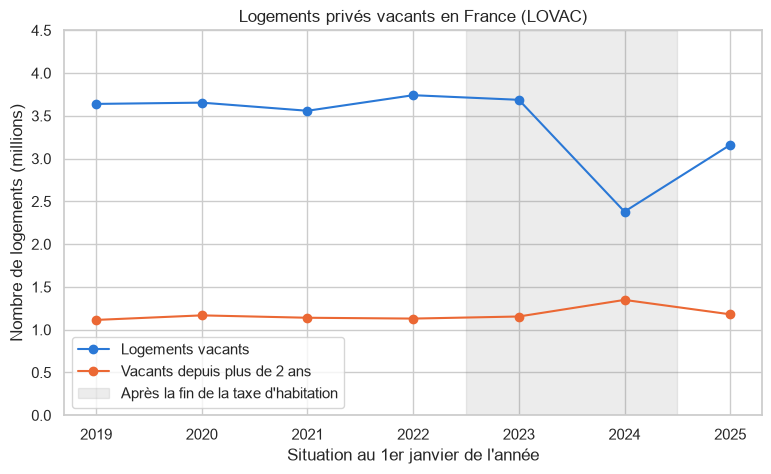

   Millésime  annee_situation  pp_vacant  pp_vacant_plus_2ans  taux_%
6       2020             2019    3639254              1114443    11.4
5       2021             2020    3654082              1167654    11.3
4       2022             2021    3559162              1139834    10.9
3       2023             2022    3741093              1130129    11.4
2       2024             2023    3687140              1154436    11.2
1       2025             2024    2380076              1348470     7.2
0       2026             2025    3160235              1179845     NaN
Millésimes 2020 -> 2021 : Spearman = 0.922
Millésimes 2021 -> 2022 : Spearman = 0.917
Millésimes 2022 -> 2023 : Spearman = 0.91
Millésimes 2023 -> 2024 : Spearman = 0.871
Millésimes 2024 -> 2025 : Spearman = 0.872


In [4]:
# Feuille FR : totaux nationaux par millésime
fr = pd.read_excel(chemin_lovac, sheet_name="FR")
fr["annee_situation"] = fr["Millésime"] - 1          # millésime N = situation au 1er janvier N-1
fr = fr.sort_values("annee_situation")

plt.figure(figsize=(9, 5))
plt.plot(fr["annee_situation"], fr["pp_vacant"] / 1e6, marker="o", color=bleu, label="Logements vacants")
plt.plot(fr["annee_situation"], fr["pp_vacant_plus_2ans"] / 1e6, marker="o", color=orange, label="Vacants depuis plus de 2 ans")
plt.axvspan(2022.5, 2024.5, color="grey", alpha=0.15, label="Après la fin de la taxe d'habitation")
plt.title("Logements privés vacants en France (LOVAC)")
plt.xlabel("Situation au 1er janvier de l'année")
plt.ylabel("Nombre de logements (millions)")
plt.ylim(0, 4.5)
plt.legend()
plt.show()

# Validation 1 : les chiffres et le taux national (quand le parc est connu)
fr["taux_%"] = (fr["pp_vacant"] / fr["ff_pp_total"] * 100).round(1)
print(fr[["Millésime", "annee_situation", "pp_vacant", "pp_vacant_plus_2ans", "taux_%"]])

# Validation 2 : le classement des communes est-il stable d'une année à l'autre ?
# Corrélation de Spearman entre les taux de vacance de deux millésimes consécutifs
for a, b in [("20", "21"), ("21", "22"), ("22", "23"), ("23", "24"), ("24", "25")]:
    ta = lovac["pp_vacant_" + a] / lovac["ff_pp_total_" + a]
    tb = lovac["pp_vacant_" + b] / lovac["ff_pp_total_" + b]
    ok = ta.notna() & tb.notna()
    print("Millésimes 20" + a, "-> 20" + b, ": Spearman =", round(stats.spearmanr(ta[ok], tb[ok])[0], 3))

**Interprétation du graphique :** de 2019 à 2023, le nombre de logements privés vacants est stable, autour de 3,6-3,7 millions (taux national d'environ 11 %). En 2024, il chute brutalement à 2,38 millions (7,2 %), puis remonte à 3,16 millions en 2025. Une baisse d'un tiers en un an, suivie d'une remontée, ne correspond à aucune évolution réelle du marché : c'est l'effet du changement de collecte après la fin de la taxe d'habitation (dispositif GMBI). La vacance de plus de 2 ans reste stable (1,1 à 1,35 million) : elle est moins touchée par la rupture.

**Choix de la validation :** une rupture de collecte peut fausser les **niveaux** sans fausser la **position relative** des communes. On mesure la stabilité du classement des communes entre deux millésimes consécutifs avec la corrélation de Spearman (fondée sur les rangs).

**Interprétation du test :** le classement est très stable avant la rupture (Spearman de 0,91 à 0,92 entre millésimes successifs) et reste élevé après (0,87). Les communes très vacantes restent très vacantes, même si le niveau national est faussé.

**Avis métier :** il ne faut pas utiliser LOVAC pour mesurer l'**évolution** de la vacance autour de 2023-2024. En revanche, il reste fiable pour **comparer les communes entre elles** une année donnée. Pour le modèle, il vaut mieux utiliser un indicateur relatif (rang ou écart à la moyenne nationale de l'année) qu'un niveau brut, et signaler les millésimes après rupture.

## Graphique 2 : le secret statistique selon la taille de la commune

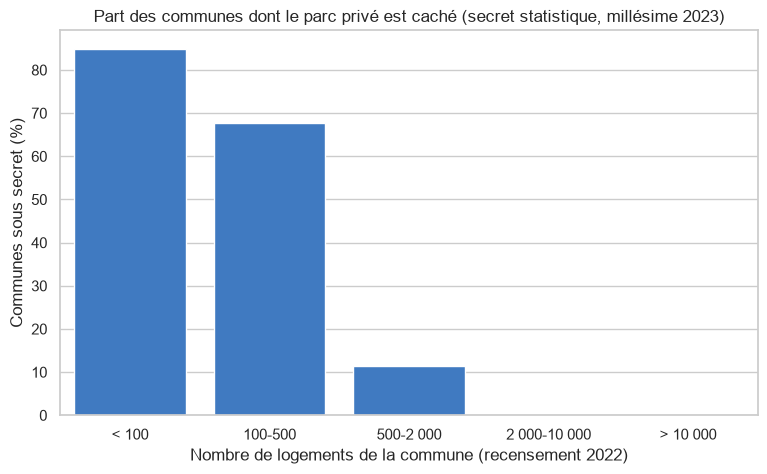

taille
< 100           84.9
100-500         67.6
500-2 000       11.3
2 000-10 000     0.2
> 10 000         0.0
Name: parc_secret, dtype: float64
Part des logements situés dans une commune au parc connu : 90.6 %
khi-deux : 12960 | p-value : 0.0 | V de Cramér : 0.61


In [5]:
compar["taille"] = pd.cut(compar["P22_LOG"], bins=[0, 100, 500, 2000, 10000, 2000000],
                          labels=["< 100", "100-500", "500-2 000", "2 000-10 000", "> 10 000"])
compar["parc_secret"] = compar["ff_pp_total_23"].isna()     # parc privé caché (millésime 2023)

part_secret = compar.groupby("taille", observed=True)["parc_secret"].mean() * 100

plt.figure(figsize=(9, 5))
sns.barplot(x=part_secret.index, y=part_secret.values, color=bleu)
plt.title("Part des communes dont le parc privé est caché (secret statistique, millésime 2023)")
plt.xlabel("Nombre de logements de la commune (recensement 2022)")
plt.ylabel("Communes sous secret (%)")
plt.show()

# Validation 1 : part de secret et part des logements couverts
print(part_secret.round(1))
couvert = compar[~compar["parc_secret"]]["P22_LOG"].sum() / compar["P22_LOG"].sum() * 100
print("Part des logements situés dans une commune au parc connu :", round(couvert, 1), "%")

# Validation 2 : khi-deux taille × secret + V de Cramér
contingence = pd.crosstab(compar["taille"], compar["parc_secret"])
khi2, p, ddl, attendu = stats.chi2_contingency(contingence)
v_cramer = np.sqrt(khi2 / (contingence.values.sum() * (min(contingence.shape) - 1)))
print("khi-deux :", round(khi2), "| p-value :", p, "| V de Cramér :", round(v_cramer, 2))

**Interprétation du graphique :** le secret statistique dépend presque entièrement de la taille de la commune. Le parc privé est caché pour 85 % des communes de moins de 100 logements et 68 % de celles de 100 à 500, contre 11 % de 500 à 2 000 et pratiquement aucune au-delà. Ce sont donc les villages qui disparaissent des données.

**Choix du test :** on croise deux variables qualitatives (classe de taille, secret oui ou non) : c'est le cas du khi-deux. Le V de Cramér mesure l'intensité du lien.

**Interprétation du test :** le khi-deux est très significatif (12 960, p ≈ 0) et le V de Cramér vaut **0,61** : un lien **fort**. Les valeurs manquantes ne sont donc pas réparties au hasard : supprimer les communes sous secret reviendrait à retirer une grande partie du monde rural.

**Avis métier :** en nombre de logements, la perte est limitée : les communes au parc connu regroupent 90,6 % des logements, donc l'essentiel des ventes. Pour ne pas abandonner les villages, on complète leur taux par celui de leur intercommunalité (EPCI), en signalant ces valeurs dans une colonne à part.

## Graphique 3 : vacance LOVAC et vacance du recensement

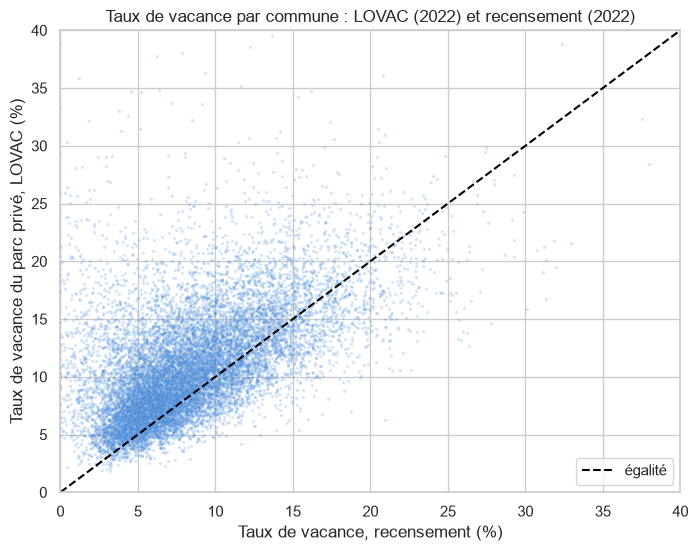

Communes comparées : 15105
Médianes : recensement 7.5 % | LOVAC 9.9 %
Part des communes où LOVAC > recensement : 74.6 %
Pearson : PearsonRResult(statistic=np.float64(0.5305779948259279), pvalue=np.float64(0.0))
Spearman : SignificanceResult(statistic=np.float64(0.585102000682307), pvalue=np.float64(0.0))


In [6]:
# Millésime 2023 (situation au 1er janvier 2022), le plus proche du recensement 2022
compar["taux_lovac"] = compar["pp_vacant_23"] / compar["ff_pp_total_23"] * 100
compar["taux_recensement"] = compar["P22_LOGVAC"] / compar["P22_LOG"] * 100
k = compar.dropna(subset=["taux_lovac", "taux_recensement"])
k = k[k["P22_LOG"] >= 50]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=k, x="taux_recensement", y="taux_lovac", s=5, alpha=0.2, color=bleu)
plt.plot([0, 40], [0, 40], color="black", linestyle="--", label="égalité")
plt.xlim(0, 40)
plt.ylim(0, 40)
plt.title("Taux de vacance par commune : LOVAC (2022) et recensement (2022)")
plt.xlabel("Taux de vacance, recensement (%)")
plt.ylabel("Taux de vacance du parc privé, LOVAC (%)")
plt.legend()
plt.show()

# Validation : niveaux, puis corrélations
print("Communes comparées :", len(k))
print("Médianes : recensement", round(k["taux_recensement"].median(), 1), "% | LOVAC", round(k["taux_lovac"].median(), 1), "%")
print("Part des communes où LOVAC > recensement :", round((k["taux_lovac"] > k["taux_recensement"]).mean() * 100, 1), "%")
print("Pearson :", stats.pearsonr(k["taux_recensement"], k["taux_lovac"]))
print("Spearman :", stats.spearmanr(k["taux_recensement"], k["taux_lovac"]))

**Interprétation du graphique :** les deux mesures vont dans le même sens : les communes très vacantes selon le recensement le sont aussi selon LOVAC. Mais la plupart des points sont **au-dessus de la diagonale** : LOVAC donne une vacance plus élevée dans 74,6 % des 15 105 communes comparées (médiane de 9,9 % contre 7,5 %). Le nuage est large : pour un même taux au recensement, LOVAC varie beaucoup.

**Choix du test :** deux variables quantitatives continues : Pearson (lien linéaire) et Spearman (lien monotone, moins sensible aux valeurs extrêmes comme celles de la Guyane). Le coefficient sert de taille d'effet.

**Interprétation du test :** Pearson (r = 0,53) et Spearman (ρ = 0,59) indiquent un lien **fort** (au-delà de 0,5), mais loin d'une identité. Spearman est un peu plus élevé : les valeurs extrêmes affaiblissent le lien linéaire.

**Avis métier :** les deux sources mesurent la même réalité avec des méthodes différentes : vacance observée par l'enquêteur contre vacance fiscale, tout le parc contre parc privé. Elles ne sont pas redondantes au point d'en écarter une d'office : LOVAC apporte la dimension annuelle et la vacance longue. Leur corrélation reste assez élevée pour qu'il faille vérifier, lors de la modélisation, qu'elles ne se font pas concurrence (importance des variables).

## Preprocessing

| Étape | Action | Pourquoi | Résultat attendu |
|---|---|---|---|
| 1. Chargement | Lire la feuille « COM open data » en texte | Les « s » empêchent la lecture en nombres | 34 912 × 28 |
| 2. Secret | Remplacer « s » par une valeur manquante, puis convertir en nombres | « s » signifie « caché », pas zéro | 310 532 valeurs manquantes |
| 3. Format long | Une ligne par commune et par millésime | Indispensable pour joindre avec les ventes par année | 244 384 lignes (34 912 × 7) |
| 4. Dates | Ajouter l'année de situation (N-1) et l'année de vente associée (N) | Éviter la confusion de dates et la fuite de données | — |
| 5. Indicateurs | Taux de vacance, taux de vacance de plus de 2 ans, part de la vacance longue parmi les vacants | Les effectifs bruts dépendent de la taille de la commune | Taux entre 0 et 100 |
| 6. Signalements | Rupture (millésimes 2024 et suivants), Alsace-Moselle, Mayotte, code EPCI | Choix d'exclusion faits plus tard, à la jointure | — |
| 7. Taux cachés | Remplacer le taux manquant par celui de l'EPCI (sommes des communes connues), avec un signalement | Ne pas perdre les communes rurales sous secret | Taux complété pour toutes les communes de 2020 à 2025 |
| 8. Contrôles | Unicité commune × millésime, bornes, cohérence vacants 2 ans ≤ vacants, taux national | Vérifier avant d'enregistrer | Taux national d'environ 11 %, conforme à la feuille FR |
| 9. Enregistrement | Nouveau fichier dans `data/processed/` | Le fichier d'origine reste intact | 244 384 lignes × 19 colonnes |

In [8]:
import numpy as np
import pandas as pd
from pathlib import Path

# ═══ ÉTAPE 0 : chemins (à adapter) ═══════════════════════════════════════════
chemin_entree = "../data/lovac-open-data-2020-a-2026.xlsx"
chemin_sortie = "../data/processed/lovac_commune_annee.csv"


# ═══ ÉTAPE 1 : chargement de la feuille communale, tout en texte ════════════
# Les "s" (secret statistique) empêchent de lire les chiffres directement en nombres
lovac = pd.read_excel(chemin_entree, sheet_name="COM open data", dtype=str)
print("Chargé :", lovac.shape)


# ═══ ÉTAPE 2 : secret statistique -> valeur manquante, puis conversion en nombres ═
colonnes_chiffres = []
for col in lovac.columns:
    if col.startswith("pp_") or col.startswith("ff_"):
        colonnes_chiffres.append(col)

for col in colonnes_chiffres:
    lovac[col] = lovac[col].replace("s", np.nan)          # "s" = valeur cachée, pas zéro !
    lovac[col] = pd.to_numeric(lovac[col])                # texte -> nombre
print("Valeurs manquantes (ex-secret) :", lovac[colonnes_chiffres].isna().sum().sum())


# ═══ ÉTAPE 3 : format large -> format long (une ligne par commune et par millésime) ═
# Dans le fichier, chaque millésime a ses propres colonnes (pp_vacant_20, pp_vacant_21...).
# On empile les millésimes pour obtenir : commune | millésime | vacants | vacants 2 ans | parc
morceaux = []
for annee in [2020, 2021, 2022, 2023, 2024, 2025, 2026]:
    suffixe = str(annee)[2:]                              # 2023 -> "23"
    morceau = pd.DataFrame({
        "COM": lovac["CODGEO_26"],
        "millesime": annee,
        "vacants": lovac["pp_vacant_" + suffixe],
        "vacants_2ans": lovac["pp_vacant_plus_2ans_" + suffixe],
    })
    # Le parc privé total n'existe pas pour le millésime 2026
    if "ff_pp_total_" + suffixe in lovac.columns:
        morceau["parc_prive"] = lovac["ff_pp_total_" + suffixe]
    else:
        morceau["parc_prive"] = np.nan
    morceaux.append(morceau)

lovac_long = pd.concat(morceaux, ignore_index=True)
print("Format long :", lovac_long.shape)        # 34 912 communes × 7 millésimes


# ═══ ÉTAPE 4 : dates ═════════════════════════════════════════════════════════
# Le millésime N décrit la situation au 1er janvier N-1 (ex. pp_vacant_26 -> 01/01/2025)
lovac_long["annee_situation"] = lovac_long["millesime"] - 1

# Règle "information de l'année d'avant" : pour une vente de l'année N, on utilisera le
# millésime N (situation au 1er janvier N-1, publiée au milieu de l'année N).
lovac_long["annee_vente_associee"] = lovac_long["millesime"]


# ═══ ÉTAPE 5 : création des indicateurs ══════════════════════════════════════
def ratio(numerateur, denominateur):
    return (numerateur / denominateur.replace(0, np.nan)) * 100

# Taux de vacance du parc privé
lovac_long["taux_vacance_lovac"] = ratio(lovac_long["vacants"], lovac_long["parc_prive"])
# Taux de vacance de plus de 2 ans (vacance "structurelle")
lovac_long["taux_vacance_2ans"] = ratio(lovac_long["vacants_2ans"], lovac_long["parc_prive"])
# Part de la vacance longue parmi les logements vacants (ne dépend pas du parc total)
lovac_long["part_longue_parmi_vacants"] = ratio(lovac_long["vacants_2ans"], lovac_long["vacants"])


# ═══ ÉTAPE 6 : colonnes d'aide ═══════════════════════════════════════════════
# Rupture de série : la fin de la taxe d'habitation (2023) change la collecte (dispositif GMBI).
# On signale les millésimes 2024 et suivants, à ne pas comparer directement aux précédents.
lovac_long["apres_rupture"] = lovac_long["millesime"] >= 2024

# Département, Alsace-Moselle (absente de DVF+), Mayotte (absente de DVF)
lovac_long["dep"] = np.where(lovac_long["COM"].str[:2] == "97",
                             lovac_long["COM"].str[:3], lovac_long["COM"].str[:2])
lovac_long["alsace_moselle"] = lovac_long["dep"].isin(["57", "67", "68"])
lovac_long["mayotte"] = lovac_long["dep"] == "976"

# Code EPCI (intercommunalité) : utile pour compléter les communes sous secret
epci = lovac[["CODGEO_26", "EPCI_26"]]
epci.columns = ["COM", "EPCI"]
lovac_long = lovac_long.merge(epci, on="COM", how="left")

# Code de la commune entière pour Paris, Lyon et Marseille (75056, 69123, 13055),
# utile pour les sources codées sans arrondissements (table des bassins de vie)
lovac_long["COM_ENTIERE"] = lovac_long["COM"]
lovac_long.loc[lovac_long["COM"].str[:3] == "751", "COM_ENTIERE"] = "75056"
lovac_long.loc[lovac_long["COM"].str[:4] == "6938", "COM_ENTIERE"] = "69123"
lovac_long.loc[lovac_long["COM"].str[:3] == "132", "COM_ENTIERE"] = "13055"

# ═══ ÉTAPE 7 : compléter les taux cachés par le taux de l'intercommunalité (EPCI) ═
# Le parc privé est secret pour ~53 % des communes (surtout les petites) : leur taux est inconnu.
# On calcule le taux de leur EPCI (sommes des communes connues) et on l'utilise à la place,
# en gardant une colonne qui signale les valeurs remplacées.
connues = lovac_long[lovac_long["taux_vacance_lovac"].notna()]
taux_epci = connues.groupby(["EPCI", "millesime"])[["vacants", "parc_prive"]].sum().reset_index()
taux_epci["taux_vacance_epci"] = ratio(taux_epci["vacants"], taux_epci["parc_prive"])
lovac_long = lovac_long.merge(taux_epci[["EPCI", "millesime", "taux_vacance_epci"]],
                              on=["EPCI", "millesime"], how="left")

lovac_long["taux_impute"] = lovac_long["taux_vacance_lovac"].isna() & lovac_long["taux_vacance_epci"].notna()
lovac_long["taux_vacance_complete"] = lovac_long["taux_vacance_lovac"].fillna(lovac_long["taux_vacance_epci"])


# ═══ ÉTAPE 8 : contrôles ═════════════════════════════════════════════════════
print("Une ligne par commune et par millésime :",
      not lovac_long.duplicated(subset=["COM", "millesime"]).any())

# Part de valeurs manquantes par millésime (secret statistique)
colonnes_a_verifier = ["vacants", "vacants_2ans", "parc_prive", "taux_vacance_lovac", "taux_vacance_complete"]
print((lovac_long[colonnes_a_verifier].isna().groupby(lovac_long["millesime"]).mean() * 100).round(1))
print("Taux remplacés par celui de l'EPCI :", lovac_long["taux_impute"].sum())

# Les taux doivent être entre 0 et 100
for col in ["taux_vacance_lovac", "taux_vacance_2ans", "part_longue_parmi_vacants", "taux_vacance_complete"]:
    hors_bornes = ((lovac_long[col] < 0) | (lovac_long[col] > 100)).sum()
    print(col, ": valeurs hors de [0, 100] =", hors_bornes)

# Cohérence : les vacants de plus de 2 ans sont une partie des vacants
print("Vacants 2 ans > vacants :", (lovac_long["vacants_2ans"] > lovac_long["vacants"]).sum())

# Ordre de grandeur : taux national par millésime (sommes, pas moyenne des taux),
# calculé sur les seules communes où vacants ET parc sont connus (même périmètre)
national = connues.groupby("millesime")[["vacants", "parc_prive"]].sum()
national["taux_%"] = (national["vacants"] / national["parc_prive"] * 100).round(1)
print(national)


# ═══ ÉTAPE 9 : enregistrement dans un NOUVEAU fichier ═══════════════════════
Path(chemin_sortie).parent.mkdir(exist_ok=True)
lovac_long.to_csv(chemin_sortie, sep=";", index=False)
print("Enregistré :", lovac_long.shape)

Chargé : (34912, 28)
Valeurs manquantes (ex-secret) : 310532
Format long : (244384, 5)
Une ligne par commune et par millésime : True
           vacants  vacants_2ans  parc_prive  taux_vacance_lovac  \
millesime                                                          
2020          21.2          58.1        53.3                56.9   
2021          20.6          57.4        53.1                56.7   
2022          21.4          58.3        53.0                56.8   
2023          20.6          56.8        52.9                56.6   
2024          19.7          77.1        52.7                56.3   
2025          26.9          63.4        52.5                57.6   
2026          19.7          50.9       100.0               100.0   

           taux_vacance_complete  
millesime                         
2020                         0.0  
2021                         0.0  
2022                         0.0  
2023                         0.0  
2024                         0.0  
2025     